In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('images', exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [5]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(url, sep=';')

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
df.describe()

Shape: (1599, 12)

Data types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

Summary statistics:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


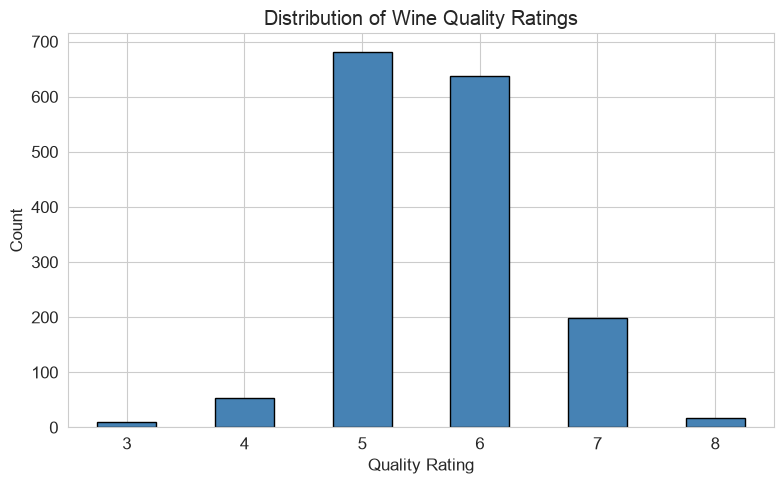

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
df['quality'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='black', ax=ax)
ax.set_xlabel('Quality Rating')
ax.set_ylabel('Count')
ax.set_title('Distribution of Wine Quality Ratings')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.savefig('images/quality_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

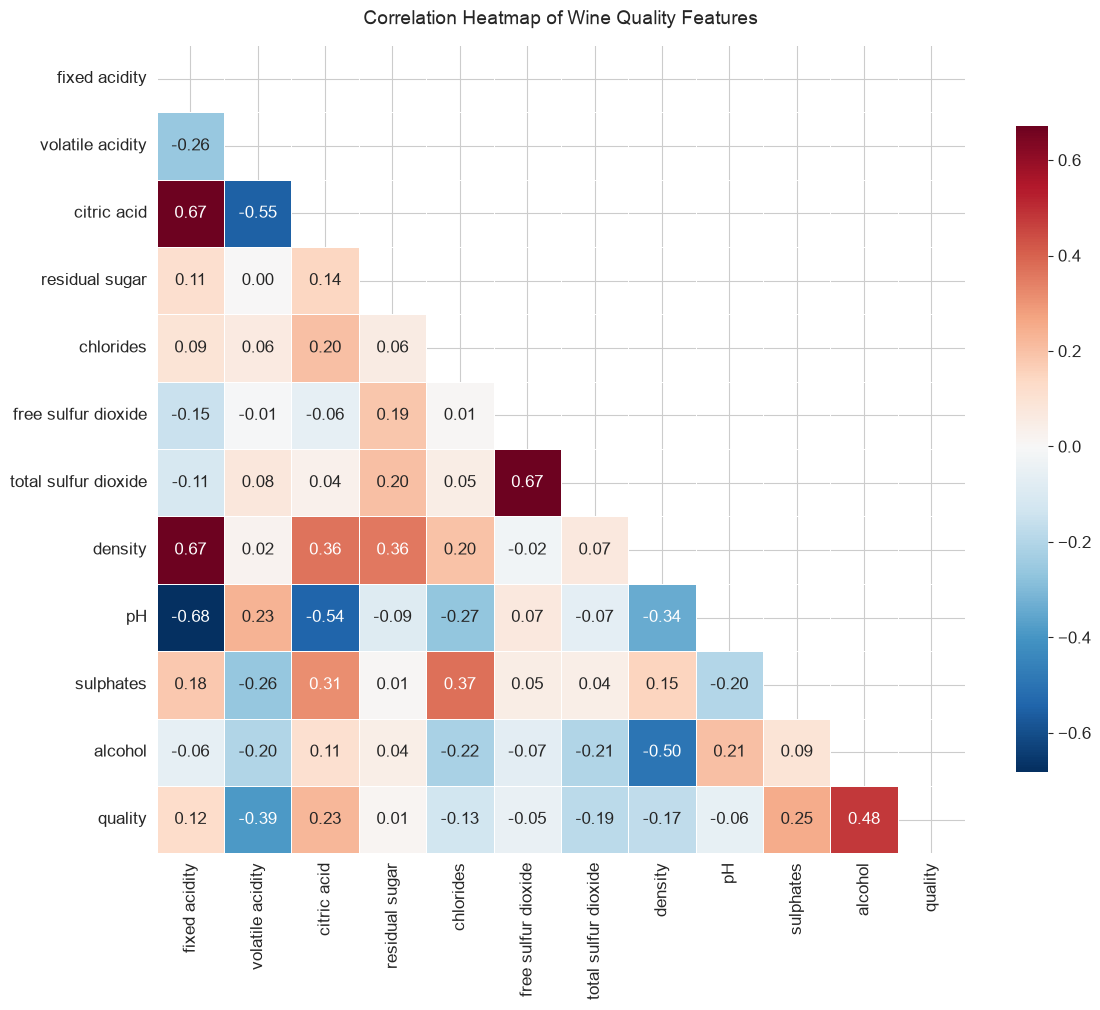

Correlation with quality (sorted):
quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64


In [8]:
plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap of Wine Quality Features', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig('images/fig1_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print("Correlation with quality (sorted):")
print(corr['quality'].sort_values(ascending=False))

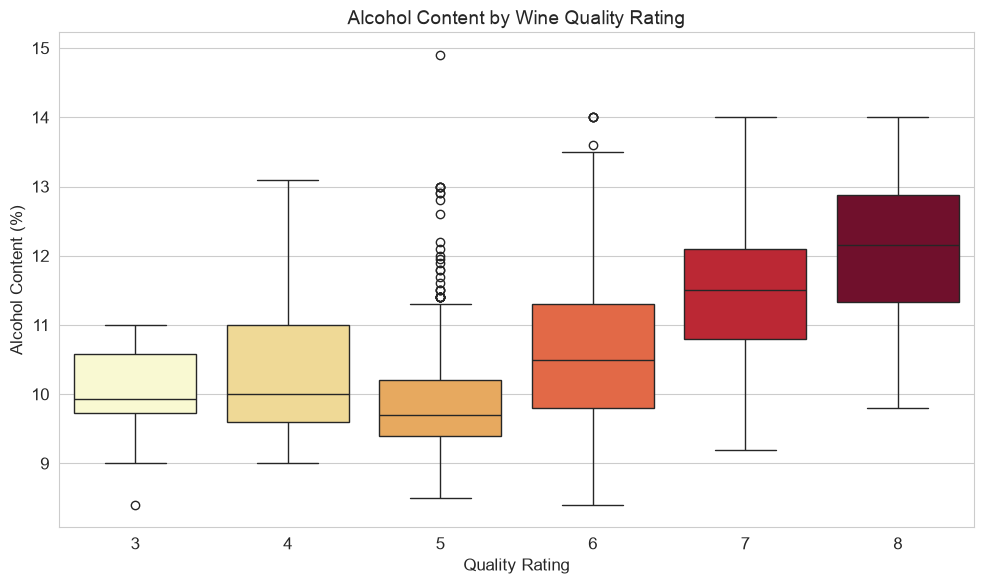

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='quality', y='alcohol', data=df, hue='quality',
            palette='YlOrRd', legend=False, ax=ax)
ax.set_xlabel('Quality Rating', fontsize=12)
ax.set_ylabel('Alcohol Content (%)', fontsize=12)
ax.set_title('Alcohol Content by Wine Quality Rating', fontsize=14)
plt.tight_layout()
plt.savefig('images/fig2_alcohol_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

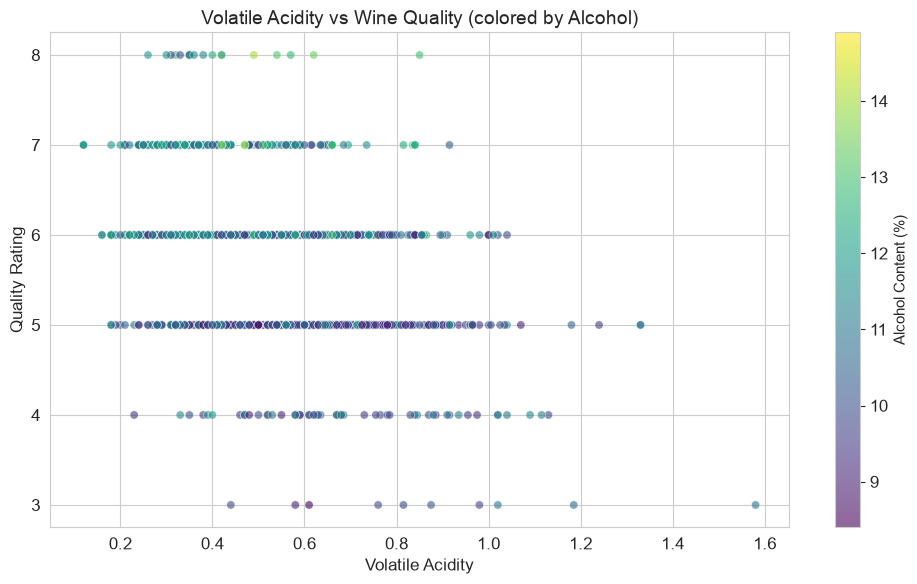

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(df['volatile acidity'], df['quality'],
                     c=df['alcohol'], cmap='viridis', alpha=0.6, edgecolors='w', linewidth=0.5)
ax.set_xlabel('Volatile Acidity', fontsize=12)
ax.set_ylabel('Quality Rating', fontsize=12)
ax.set_title('Volatile Acidity vs Wine Quality (colored by Alcohol)', fontsize=14)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Alcohol Content (%)', fontsize=11)
plt.tight_layout()
plt.savefig('images/fig3_volatile_acidity_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
group_means = df.groupby('quality').mean().round(3)
print("Mean feature values by quality rating:")
group_means

Mean feature values by quality rating:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360,0.885,0.171,2.635,0.123,11.000,24.900,0.997,3.398,0.570,9.955
4,7.779,0.694,0.174,2.694,0.091,12.264,36.245,0.997,3.382,0.596,10.265
5,8.167,0.577,0.244,2.529,0.093,16.984,56.514,0.997,3.305,0.621,9.900
6,8.347,0.497,0.274,2.477,0.085,15.712,40.870,0.997,3.318,0.675,10.630
7,8.872,0.404,0.375,2.721,0.077,14.045,35.020,0.996,3.291,0.741,11.466
8,8.567,0.423,0.391,2.578,0.068,13.278,33.444,0.995,3.267,0.768,12.094
